# MNIST Handwritten Digit Recognition 

This notebook trains and compares three neural-network approaches on the MNIST CSV files:

1. **Dense baseline** 
2. **ANN** (fully connected neural network)
3. **CNN** (convolutional neural network)

**Before running:** put `mnist_train.csv` and `mnist_test.csv` in the same folder as this notebook. Run the cells from top to bottom.

## Import libraries

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings 
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten, Conv2D, MaxPool2D, Dropout
from tensorflow.keras.utils import to_categorical


In [6]:
df=pd.read_csv("mnist_train.csv")
df_test=pd.read_csv("mnist_test.csv")

In [7]:
df.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
df.shape

(60000, 785)

In [9]:
df.columns

Index(['label', '1x1', '1x2', '1x3', '1x4', '1x5', '1x6', '1x7', '1x8', '1x9',
       ...
       '28x19', '28x20', '28x21', '28x22', '28x23', '28x24', '28x25', '28x26',
       '28x27', '28x28'],
      dtype='str', length=785)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 785 entries, label to 28x28
dtypes: int64(785)
memory usage: 359.3 MB


In [11]:
df.isnull().sum()

label    0
1x1      0
1x2      0
1x3      0
1x4      0
        ..
28x24    0
28x25    0
28x26    0
28x27    0
28x28    0
Length: 785, dtype: int64

In [12]:
x_train=df.drop("label",axis=1) 
y_train=df["label"].values 
x_test=df_test.drop("label",axis=1) 
y_test=df_test["label"]

In [13]:
x_train.head()

,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,1x10,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
x_train_img = np.array(x_train).reshape(-1, 28, 28)
x_test_img = np.array(x_test).reshape(-1, 28, 28)

In [15]:
y_train_cat=to_categorical(y_train,10) 
y_test_cat=to_categorical(y_test,10) 

##  Model 1 — Dense baseline

In [16]:
perceptron=Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10,activation="softmax")
])

In [17]:
perceptron.compile(optimizer="sgd",loss="categorical_crossentropy",metrics=["accuracy"])

In [18]:
history_percp=perceptron.fit(x_train_img,y_train_cat,epochs=5,batch_size=32,validation_data=(x_test_img,y_test_cat),verbose=1) 

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 299us/step - accuracy: 0.8418 - loss: 325.9785 - val_accuracy: 0.8718 - val_loss: 255.6881
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 252us/step - accuracy: 0.8674 - loss: 263.5436 - val_accuracy: 0.8822 - val_loss: 237.4751
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 255us/step - accuracy: 0.8732 - loss: 249.7020 - val_accuracy: 0.8861 - val_loss: 236.5384
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 247us/step - accuracy: 0.8758 - loss: 244.9684 - val_accuracy: 0.8948 - val_loss: 206.5268
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 249us/step - accuracy: 0.8760 - loss: 242.9987 - val_accuracy: 0.8946 - val_loss: 221.4811


In [19]:
acc_percp = perceptron.evaluate(x_test_img, y_test_cat, verbose=0)[1]
acc_percp

0.894599974155426

##  Model 2 — Artificial Neural Network (ANN)

In [20]:
ann=Sequential([Flatten(input_shape=(28,28)), 
               Dense(128,activation="relu"), 
               Dense(64,activation="relu"), 
               Dense(10,activation="softmax"), 
               ])

In [21]:

ann.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])
history_ann=ann.fit(x_train_img,y_train_cat,epochs=5,batch_size=32,validation_data=(x_test_img,y_test_cat),verbose=1) 

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 647us/step - accuracy: 0.8587 - loss: 1.5688 - val_accuracy: 0.9021 - val_loss: 0.3808
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 588us/step - accuracy: 0.9241 - loss: 0.2889 - val_accuracy: 0.9266 - val_loss: 0.2844
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 575us/step - accuracy: 0.9434 - loss: 0.2052 - val_accuracy: 0.9488 - val_loss: 0.1884
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 589us/step - accuracy: 0.9541 - loss: 0.1652 - val_accuracy: 0.9505 - val_loss: 0.2215
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 582us/step - accuracy: 0.9603 - loss: 0.1435 - val_accuracy: 0.9434 - val_loss: 0.2146


In [22]:
acc_ann=ann.evaluate(x_test_img,y_test_cat,verbose=0)[1]
acc_ann

0.9434000253677368

##  Model 3 — Convolutional Neural Network (CNN)


In [23]:
x_train_cnn = x_train.to_numpy().reshape(-1, 28, 28, 1)
x_test_cnn = x_test.to_numpy().reshape(-1, 28, 28, 1)

In [24]:
cnn=Sequential([
    Conv2D(32,kernel_size=(3,3),activation="relu",input_shape=(28,28,1)), 
    MaxPool2D(pool_size=(2,2)), 
    Conv2D(64,kernel_size=(3,3),activation="relu"), 
    MaxPool2D(pool_size=(2,2)), 
    Flatten(),
    Dense(128,activation="relu"), 
    Dropout(0.5), 
    Dense(10,activation="softmax")    
])

In [25]:
cnn.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

In [26]:
history_cnn=cnn.fit(x_train_cnn,y_train_cat,epochs=5,batch_size=32,validation_data=(x_test_cnn,y_test_cat),verbose=1) 

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8868 - loss: 0.4954 - val_accuracy: 0.9784 - val_loss: 0.0755
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9610 - loss: 0.1367 - val_accuracy: 0.9804 - val_loss: 0.0612
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9692 - loss: 0.1062 - val_accuracy: 0.9837 - val_loss: 0.0575
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9750 - loss: 0.0890 - val_accuracy: 0.9832 - val_loss: 0.0569
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9775 - loss: 0.0795 - val_accuracy: 0.9878 - val_loss: 0.0397


In [27]:
acc_cnn=cnn.evaluate(x_test_cnn,y_test_cat,verbose=0)[1]
acc_cnn

0.9878000020980835

## Compare training and validation curves

In [28]:

def plot_training(history, title):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label="Train")
    plt.plot(history.history['val_accuracy'], label="Val")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label="Train")
    plt.plot(history.history['val_loss'], label="Val")
    plt.title(f"{title} Loss")
    plt.legend()
    plt.show()
     

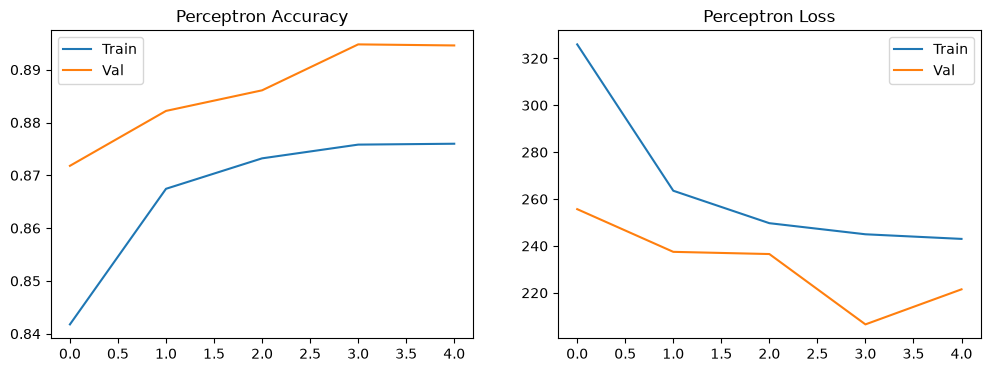

In [29]:
plot_training(history_percp, "Perceptron")

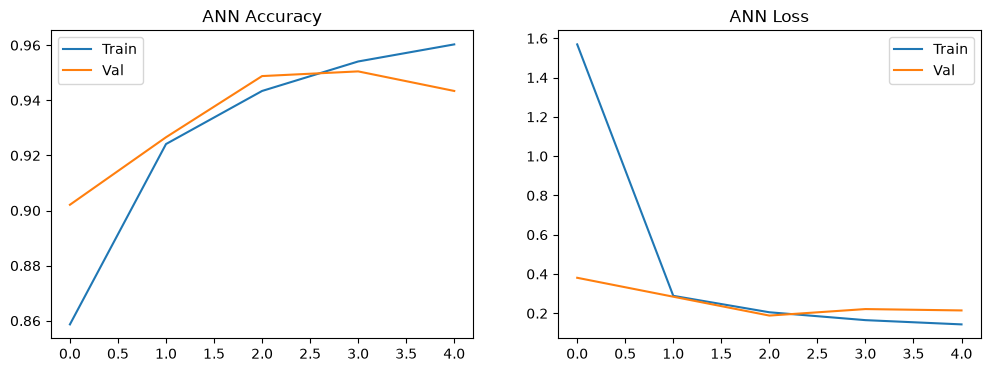

In [30]:
plot_training(history_ann, "ANN")

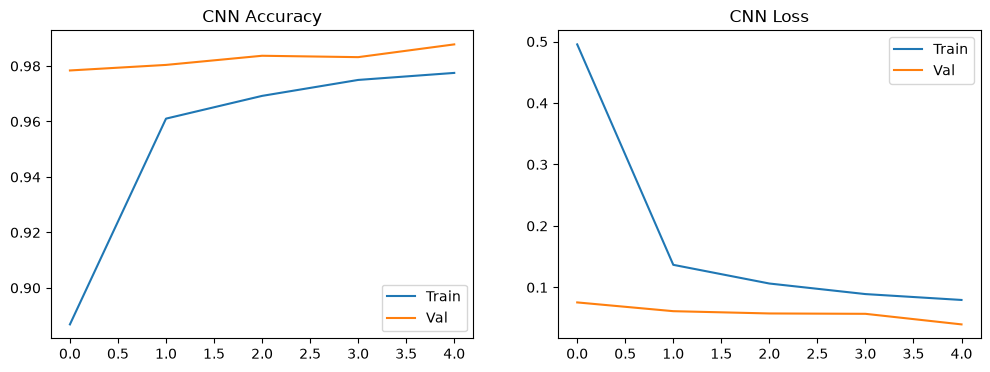

In [31]:
plot_training(history_cnn, "CNN")

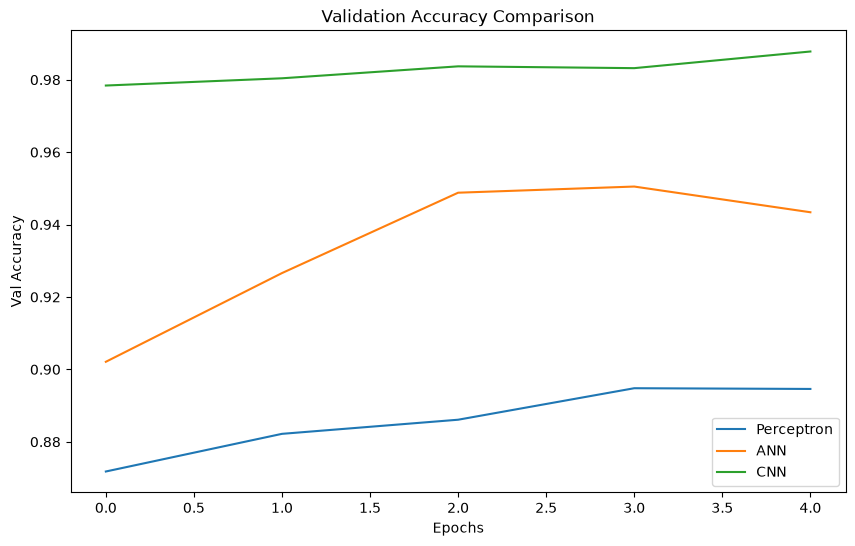

In [32]:
plt.figure(figsize=(10,6))
plt.plot(history_percp.history['val_accuracy'], label="Perceptron")
plt.plot(history_ann.history['val_accuracy'], label="ANN")
plt.plot(history_cnn.history['val_accuracy'], label="CNN")
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Val Accuracy")
plt.legend()
plt.show()

##  View sample predictions from all models

In [33]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i+1)
        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if name == "CNN" else X[idx].reshape(1, 28, 28)))
                 for model, name in zip(models, model_names)]
        plt.subplot(2, n, n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
    plt.tight_layout()
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


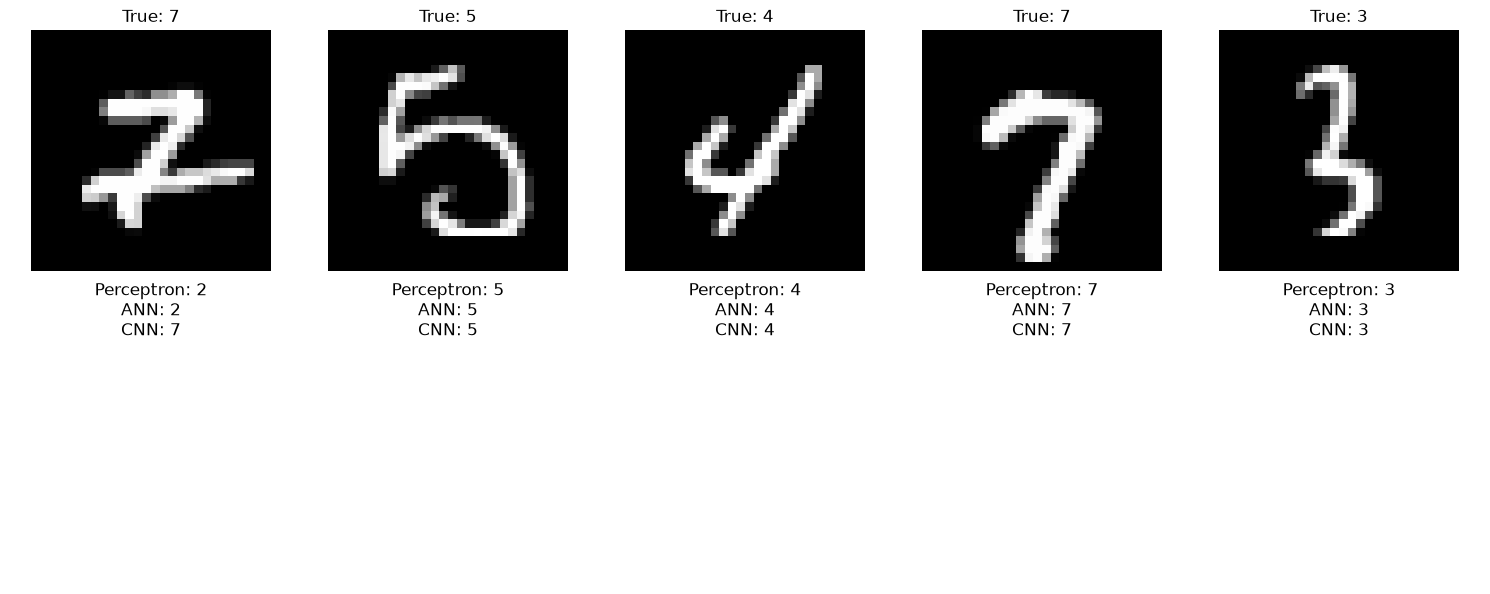

In [34]:
show_side_by_side([perceptron, ann, cnn], ["Perceptron", "ANN", "CNN"], x_test_img, x_test_cnn, y_test, 5)

## Save trained models for the Streamlit app

Run this cell after training all three models. It saves each trained Keras model in the `models` folder used by the Streamlit application.

In [35]:
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

perceptron.save(model_dir / "mnist_dense_model.keras")
ann.save(model_dir / "mnist_ann_model.keras")
cnn.save(model_dir / "mnist_cnn_model.keras")

print("Saved all three models in:", model_dir.resolve())

Saved all three models in: /Users/amansingh/Desktop/mnist_digit_app/models
